# 分析說明:讓國中霸凌加害者停手的是什麼？

這份筆記本一步一步說明報告〈別再只教受害者自保:讓國中霸凌加害者停手的是什麼？〉的分析流程。

| 步驟 | 內容 | 對應程式 |
|---|---|---|
| 1 | 資料與串連:學生兩波、家長、導師 | `bully/data.py` 的 `build()` |
| 2 | 變數怎麼定義:量表轉成有 / 沒有、角色、嚴重度 | `bully/data.py` |
| 3 | 邏輯斯迴歸與勝算比 | `bully/models.py` 的 `logit()`、`odds_ratio()` |
| 4 | 為什麼標準誤要依班級群聚校正 | `bully/models.py` |
| 5 | 累積風險指數與 AIC 模型比較 | `bully/analyses.py` 的 `cumulative()` |
| 6 | 在真實資料上重現報告數字與圖 | `run_all.py` |

**關於資料**:TIGPS 原始資料依中研院學術調查研究資料庫(SRDA)規定不能公開,因此第 2–5 節全部用**模擬的假資料**示範方法;第 6 節只有在你把 TIGPS 檔案放進 `data/` 後才會執行,而且只輸出彙總數字。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from bully import figures            # 載入時會設定中文字型
rng = np.random.default_rng(2026)
pd.set_option('display.width', 120)

## 1. 資料與串連

TIGPS(臺灣青少年成長歷程研究)2023 年從國一學生抽樣,**以班級為單位**,同時訪問學生、家長與導師,2024 年再追蹤同一批學生。

| 檔案 | 內容 | 串連鍵 |
|---|---|---|
| `TIGPSw1_s.dta` | 2023 學生(8,958 人) | `nstudent_id`、`school_class` |
| `TIGPSw2_s.dta` | 2024 學生 | `nstudent_id` |
| `TIGPSw1_p.dta` | 2023 家長 | `nstudent_id` |
| `TIGPSw1_t.dta` | 2023 導師(一班一位) | `school_class` |

學生與家長、兩波學生用**學生編號**對應;導師用**班級代碼**對應,所以同一班的學生會拿到同一份導師資料。下面用 5 位假學生示範:

In [2]:
w1 = pd.DataFrame({'id': [101, 102, 103, 104, 105], 'cls': ['A', 'A', 'B', 'B', 'B'], 'perp': [1, 0, 1, 1, 0]})
w2 = pd.DataFrame({'id': [101, 103, 104, 105], 'perp2': [0, 1, 0, 0]})          # 102 第二波沒追蹤到
parent = pd.DataFrame({'id': [101, 104], 'p_hit': [0, 1]})                      # 只有部分家長填答
teacher = pd.DataFrame({'cls': ['A', 'B'], 'notify': [1, 0]})                    # 一班一位導師

D = (w1.merge(parent, on='id', how='left')       # 家長:用學生編號
       .merge(teacher, on='cls', how='left')     # 導師:用班級代碼
       .merge(w2, on='id', how='left'))          # 第二波:用學生編號
D

,id,cls,perp,p_hit,notify,perp2
0,101,A,1,0.0,1,0.0
1,102,A,0,NaN,1,NaN
2,103,B,1,NaN,0,1.0
3,104,B,1,1.0,0,0.0
4,105,B,0,NaN,0,0.0


都用 `how='left'`(左合併),所以學生人數不會因為串連而減少,沒有家長或第二波資料的人只是那一欄是空的(`NaN`)。分析某個問題時,才只保留該問題需要的欄位都有資料的人。實際資料:8,958 位學生中 8,255 人兩波都有回答,3,180 人有家長回答管教題,237 個班有導師資料。

**加害者停手**的定義:2023 年加害(`perp=1`)、2024 年有回答的學生中,2024 年回答沒有霸凌他人。

In [3]:
S = D[(D.perp == 1) & D.perp2.notna()].copy()
S['stop'] = 1 - S.perp2
S[['id', 'cls', 'perp', 'perp2', 'stop']]

,id,cls,perp,perp2,stop
0,101,A,1,0.0,1.0
2,103,B,1,1.0,0.0
3,104,B,1,0.0,1.0


## 2. 變數怎麼定義

### 2.1 四點量表 → 有 / 沒有

問卷多是四點量表,例如「家長處罰我時會打我」:1 從不、2 很少、3 有時、4 經常。我們以 **≥ 3(有時、經常)** 當作「有」:

$$x_i = \begin{cases} 1 & \text{回答} \in \{3,4\} \\ 0 & \text{回答} \in \{1,2\} \\ \text{遺漏} & \text{其他(負值代表跳答或未答)}\end{cases}$$

程式是 `bully/data.py` 的 `yes()`:

In [4]:
from bully.data import yes
raw = pd.Series([1, 2, 3, 4, -9, -6])      # -9 未答、-6 跳答
raw_clean = raw.where(raw >= 0)            # 負值 → NaN(對應 num())
pd.DataFrame({'原始回答': raw, '轉換後': yes(raw_clean)})

,原始回答,轉換後
0,1,0.0
1,2,0.0
2,3,1.0
3,4,1.0
4,-9,NaN
5,-6,NaN


### 2.2 四種角色

「是否曾被霸凌」與「是否曾霸凌他人」兩題交叉,得到四種角色:無涉入、純受害、純加害、**加害受害**(兩者皆是)。報告發現加害受害者最難停手。

### 2.3 嚴重度

8 種霸凌行為(罵、說壞話、排擠、嘲笑、散播謠言、破壞物品、勒索、肢體)各問頻率,1 從未 … 4 經常,轉成 0–3 分後加總:

$$\text{嚴重度}_i = \sum_{k=1}^{8} (\text{頻率}_{ik} - 1), \qquad 0 \le \text{嚴重度}_i \le 24$$

至少答 5 題才計算。嚴重度當作**控制變項**:霸凌得越兇的人本來就越難停,如果不控制,很多因素看起來有關,其實只是反映嚴重度。

In [5]:
freq = pd.DataFrame(rng.integers(1, 5, size=(4, 8)), columns=[f'行為{k}' for k in range(1, 9)])
freq.iloc[3, :4] = np.nan                   # 第 4 人只答 4 題 → 不計算
freq['嚴重度'] = (freq.iloc[:, :8] - 1).sum(axis=1, min_count=5)
freq

,行為1,行為2,行為3,行為4,行為5,行為6,行為7,行為8,嚴重度
0,4.0,1.0,1.0,3.0,2,2,1,2,8.0
1,3.0,2.0,4.0,4.0,3,4,3,1,16.0
2,4.0,3.0,1.0,2.0,1,4,3,4,14.0
3,NaN,NaN,NaN,NaN,1,3,3,4,NaN


## 3. 邏輯斯迴歸與勝算比

結果變數是「停手 / 沒停手」(0/1),所以用**邏輯斯迴歸**。它假設停手機率 $p_i$ 的**對數勝算**是自變項的線性組合:

$$\log\frac{p_i}{1-p_i} = \beta_0 + \beta_1 x_{i1} + \cdots + \beta_k x_{ik}
\quad\Longleftrightarrow\quad
p_i = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_{i1} + \cdots)}}$$

- **勝算**(odds)= $p/(1-p)$。停手率 60% 的勝算是 0.6/0.4 = 1.5。
- **勝算比**(odds ratio, OR)= $e^{\beta}$:在其他變項相同時,$x$ 從 0 變 1,勝算變成幾倍。OR < 1 代表較難停手,OR > 1 代表較容易停手。

**例子**:家裡會打的加害者停手 51%,不打的 66%。

In [6]:
odds = lambda p: p / (1 - p)
print(f'會打的勝算 {odds(.51):.2f},不打的勝算 {odds(.66):.2f},粗勝算比 {odds(.51) / odds(.66):.2f}')

會打的勝算 1.04,不打的勝算 1.94,粗勝算比 0.54


粗勝算比是 0.54;報告寫 0.63,因為報告的勝算比有**控制**性別、加害嚴重度、是否同時受害、班級加害率。下面用假資料確認:我們設定真正的 $\beta$,產生資料,再看 `logit()` 能不能估回來。

In [7]:
def fake_perpetrators(n_class=150, per_class=15, class_sd=0.0, seed=1):
    # 模擬加害者資料。class_sd > 0 時,每班有自己的「班級氣氛」,同班學生的結果彼此相關
    r = np.random.default_rng(seed)
    cls = np.repeat(np.arange(n_class), per_class)
    u = r.normal(0, class_sd, n_class)[cls]                  # 班級隨機效果
    notify = r.binomial(1, 0.5, n_class)[cls]                # 班級層次變數:導師是否通知父母(同班都一樣)
    x = pd.DataFrame({'cls': cls, 'notify': notify,
                      'female': r.integers(0, 2, len(cls)),
                      'perp_sev': r.poisson(4, len(cls)),
                      'hit': r.binomial(1, 0.2, len(cls))})
    eta = 1.2 - 0.3 * x.female - 0.12 * x.perp_sev + np.log(0.6) * x.hit + u   # 真正的 OR(會打)= 0.6;notify 沒有效果
    x['stop'] = r.binomial(1, 1 / (1 + np.exp(-eta)))
    return x

F = fake_perpetrators()
from bully.models import logit, odds_ratio
m, used = logit('stop ~ female + perp_sev + hit', F)
print(f'n={len(used)};真正的 OR = 0.60;估計:', odds_ratio(m, 'hit'))

n=2250;真正的 OR = 0.60;估計: {'OR': 0.61, 'CI': [0.49, 0.77], 'p': 0.0}


估計值會在 0.6 附近(小差距是抽樣誤差),95% 信賴區間包含 0.6。`odds_ratio()` 回傳的 CI 是 $e^{\hat\beta \pm 1.96\,\widehat{SE}}$。

## 4. 為什麼標準誤要依班級群聚校正

TIGPS 是**整班抽樣**。同一班的學生有同一位導師、同一群同學,結果彼此相關。普通的標準誤假設每個人都獨立,等於把資料量高估了,因此標準誤太小、p 值太小,容易誤判顯著。

群聚穩健(cluster-robust)標準誤用「三明治」公式,把同一班的分數加總後再計算變異:

$$\widehat{V}(\hat\beta) = \underbrace{(X^\top W X)^{-1}}_{\text{麵包}}\;
\underbrace{\Big(\sum_{g=1}^{G} s_g s_g^\top\Big)}_{\text{肉}}\;
\underbrace{(X^\top W X)^{-1}}_{\text{麵包}},
\qquad s_g = \sum_{i \in \text{班級 } g} x_i\,(y_i - \hat p_i)$$

其中 $W = \text{diag}\big(\hat p_i(1-\hat p_i)\big)$,$G$ 是班級數。班內的誤差如果同方向,$s_g$ 會變大,標準誤也就變大。`statsmodels` 用 `cov_type='cluster'` 計算(另有小樣本校正)。

下面產生**有班級效果**的假資料(`class_sd=1`),比較兩種標準誤。`hit` 是個人層次變數,`notify`(導師是否通知父母)是班級層次變數,同一班的人都一樣:

In [8]:
F2 = fake_perpetrators(class_sd=1.0, seed=3)
f = 'stop ~ female + perp_sev + hit + notify'
naive = smf.logit(f, data=F2).fit(disp=0)
clus, _ = logit(f, F2)
pd.DataFrame({'普通 SE': naive.bse, '班級群聚 SE': clus.bse, '倍數': clus.bse / naive.bse,
              '普通 p': naive.pvalues, '群聚 p': clus.pvalues}).round(3)

,普通 SE,班級群聚 SE,倍數,普通 p,群聚 p
Intercept,0.120,0.164,1.373,0.000,0.000
female,0.087,0.090,1.024,0.228,0.239
perp_sev,0.022,0.020,0.939,0.000,0.000
hit,0.105,0.109,1.033,0.000,0.000
notify,0.088,0.167,1.894,0.025,0.235


個人層次變數(`hit`、`female`)兩種 SE 差不多;**班級層次變數 `notify` 的群聚 SE 明顯較大**,因為它在同一班裡完全相同,真正的資訊量接近班級數(150),而不是學生數(2,250)。如果用普通 SE,就容易把沒有效果的班級因素誤判成顯著。報告第 3.4 節檢驗的導師處理方式正是班級層次變數,所以一定要做群聚校正。

**遺漏值**:`logit()` 先刪掉公式用到的變數有遺漏的人,再把剩下的人的班級代碼傳給群聚校正,這樣班級代碼與資料列才會一一對應。所以報告中每個檢定的 n 不完全相同。

## 5. 累積風險指數

### 5.1 為什麼用累積指數

累積風險理論(Rutter, 1979;Evans, Li & Whipple, 2013)指出,影響孩子的往往不是哪一個特定的不利條件,而是**不利條件的總數**。風險因子的定義是:發生在結果之前、且與不良結果有關的特徵(Kraemer 等,1997)。報告選的 5 項都在 2023 年測量,涵蓋三個面向:

| 面向 | 風險 |
|---|---|
| 家庭 | 家裡會打(學生或家長任一方說)、家長常批評指責 |
| 個人 | 同時被欺負、網路成癮偏高(加害者內中位數以上) |
| 同儕 | 好友會惹事生非 |

$$R_i = \sum_{k=1}^{5} r_{ik}, \qquad r_{ik} \in \{0, 1\}$$

5 項都有資料才計算。這是**形成性指標**:項目之間不必高度相關(不像量表需要 Cronbach's α),因為它衡量的是「碰到幾種不利條件」,而不是某個潛在特質。

### 5.2 檢驗方式

1. **階梯**:畫出 $R = 0, 1, 2, 3, 4+$ 各組的停手率,看是否逐級下降。
2. **每多一項的勝算比**:把 $R$ 當連續變項放進 logit,$e^{\beta_R}$ 就是每多一項風險、停手勝算變成的倍數。
3. **AIC 比較**:$\text{AIC} = 2k - 2\ln\hat L$($k$ 為參數個數、$\hat L$ 為概似值),越小越好。比較「合成一個指數」與「五項分開放入」:如果指數的 AIC 較小,代表用一個數字描述就夠了,不需要五個參數。

用假資料示範:

In [9]:
r = np.random.default_rng(7)
n = 1500
Rk = pd.DataFrame(r.binomial(1, [.25, .5, .7, .5, .3], size=(n, 5)), columns=['hit', 'criticize', 'victim', 'addict', 'friend'])
Rk['cls'] = r.integers(0, 150, n); Rk['female'] = r.integers(0, 2, n)
Rk['risk'] = Rk[['hit', 'criticize', 'victim', 'addict', 'friend']].sum(axis=1)
eta = 1.5 + np.log(0.66) * Rk.risk                          # 設定:每多一項 OR = 0.66
Rk['stop'] = r.binomial(1, 1 / (1 + np.exp(-eta)))

from bully.models import ladder
print('階梯:', ladder(Rk, 'risk', 'stop', cap=4))
m_idx, _ = logit('stop ~ female + risk', Rk)
m_sep, _ = logit('stop ~ female + hit + criticize + victim + addict + friend', Rk)
print('每多一項:', odds_ratio(m_idx, 'risk'))
print(f'AIC:指數 {m_idx.aic:.1f};分開 {m_sep.aic:.1f}')

階梯: {'k': [0, 1, 2, 3, 4], 'rate': [69.8, 74.2, 65.7, 54.0, 45.4], 'n': [63, 287, 528, 459, 163], 'N': 1500}
每多一項: {'OR': 0.69, 'CI': [0.62, 0.77], 'p': 0.0}
AIC:指數 1952.8;分開 1955.5


因為假資料就是「每一項效果都一樣」產生的,指數模型用 1 個參數就能描述,AIC 會比 5 個參數的模型小。實際資料:AIC 696 對 703(n=553),支持用累積指數。

**保護因子**用同樣方法:喜歡學校、班級凝聚力高、導師自評師生親近,三項都在 2023 年測量,早於結果。

## 6. 在真實資料上重現報告

把 TIGPS 檔案放進 `data/`(見 `data/README.md`)後,執行下面的程式,就會重算報告第 3 節的所有數字並畫出 4 張圖。只會顯示彙總結果,不會顯示任何個人資料。命令列也可以直接執行 `python run_all.py`。

In [10]:
from bully.config import DATA_DIR, FILES
HAS_DATA = all(any(DATA_DIR.rglob(f)) for f in FILES.values())
print('找到 TIGPS 資料' if HAS_DATA else f'沒有找到 TIGPS 資料({DATA_DIR}),以下略過')

找到 TIGPS 資料


In [11]:
if HAS_DATA:
    from bully.data import build, victims, perpetrators
    from bully import analyses as A
    D, info = build(); V, S = victims(D), perpetrators(D)
    print('樣本:', info)
    vc = A.victim_coping(V)
    print(f"\n3.1 受害者 {vc['n_受害者']:,} 人,一年後脫離 {vc['脫離率']}%")
    display(pd.DataFrame(vc['因應']).T[['有', '沒有', 'OR', 'p']])

樣本: {'學生_2023': 8958, '兩波配對': 8255, '配到家長問卷': 3180, '配到導師問卷_班級數': 237}

3.1 受害者 2,111 人,一年後脫離 54.7%


,有,沒有,OR,p
告訴老師,52.8,53.8,1.0,0.977
告訴家人,52.3,54.1,0.96,0.733
告訴同學朋友,50.6,54.9,0.93,0.506
要求對方停止,53.6,53.6,1.06,0.552
好好說明澄清,55.5,52.3,1.09,0.332
忽略,54.2,53.0,1.06,0.493
回擊對抗,49.3,55.4,0.89,0.265


In [12]:
if HAS_DATA:
    fl = A.flow(D)
    print('3.2 加害者一年後的去向(人數)'); display(pd.DataFrame(fl['人數']).T)
    ind = A.individual_factors(S)
    print(f"\n3.3 加害者 {ind['n_加害者']:,} 人,停手 {ind['停手率']}%;個別因素:")
    display(pd.DataFrame({k: v for k, v in ind.items() if isinstance(v, dict)}).T[['有', '沒有', 'n有', 'n沒有', 'OR', 'p']])

3.2 加害者一年後的去向(人數)


,無涉入,純受害,純加害,加害受害
純加害,216,31,41,57
加害受害,327,137,71,290



3.3 加害者 1,182 人,停手 60.5%;個別因素:


,有,沒有,n有,n沒有,OR,p
家裡會打(學生或家長說),51.0,66.1,145,610,0.63,0.027
家長常批評指責,54.7,69.7,300,261,0.59,0.005
同時也被欺負,56.2,71.0,833,348,0.49,0.0
也在網路上霸凌,49.4,64.5,316,861,0.6,0.0
網路成癮偏高,56.0,66.2,648,532,0.73,0.011
跟導師親近(2024 學生自評),63.1,56.2,691,480,1.35,0.021


In [13]:
if HAS_DATA:
    cu = A.cumulative(S)
    for k in ['risk5', 'risk4_nofamily', 'prot3']:
        c = cu[k]; print(f"{k}(n={c['N']}):停手率 {c['rate']},每多一項 OR={c['每多一項']['OR']} p={c['每多一項']['p']}")
    print('AIC:', cu['AIC'])
    nd = A.no_difference(S)
    print('\n3.4 看不出差別:'); display(pd.DataFrame({k: v for k, v in nd.items() if isinstance(v, dict)}).T[['有', '沒有', 'n有', 'n沒有', 'OR', 'p']])

risk5(n=558):停手率 [78.8, 80.2, 69.6, 58.4, 44.2],每多一項 OR=0.66 p=0.0
risk4_nofamily(n=1173):停手率 [72.2, 72.4, 62.4, 56.0, 39.0],每多一項 OR=0.7 p=0.0
prot3(n=812):停手率 [43.6, 56.1, 59.5, 66.8],每多一項 OR=1.24 p=0.012
AIC: {'n': 553, '指數': 696.2, '分開': 702.9}



3.4 看不出差別:


,有,沒有,n有,n沒有,OR,p
父母離婚,61.1,60.6,175,971,1.03,0.878
家境不富裕,59.0,61.2,344,836,0.89,0.348
導師:通知父母,60.0,65.3,752,75,0.74,0.276
導師:請輔導老師協助,59.1,63.4,570,257,0.76,0.093
導師:處罰學生,62.1,59.3,346,481,1.1,0.524
導師:召開學生家長會議,62.8,59.4,258,569,1.09,0.636
導師:隔開雙方,63.0,59.6,200,627,1.13,0.473
肢體或財物霸凌,56.9,63.8,564,618,1.04,0.772


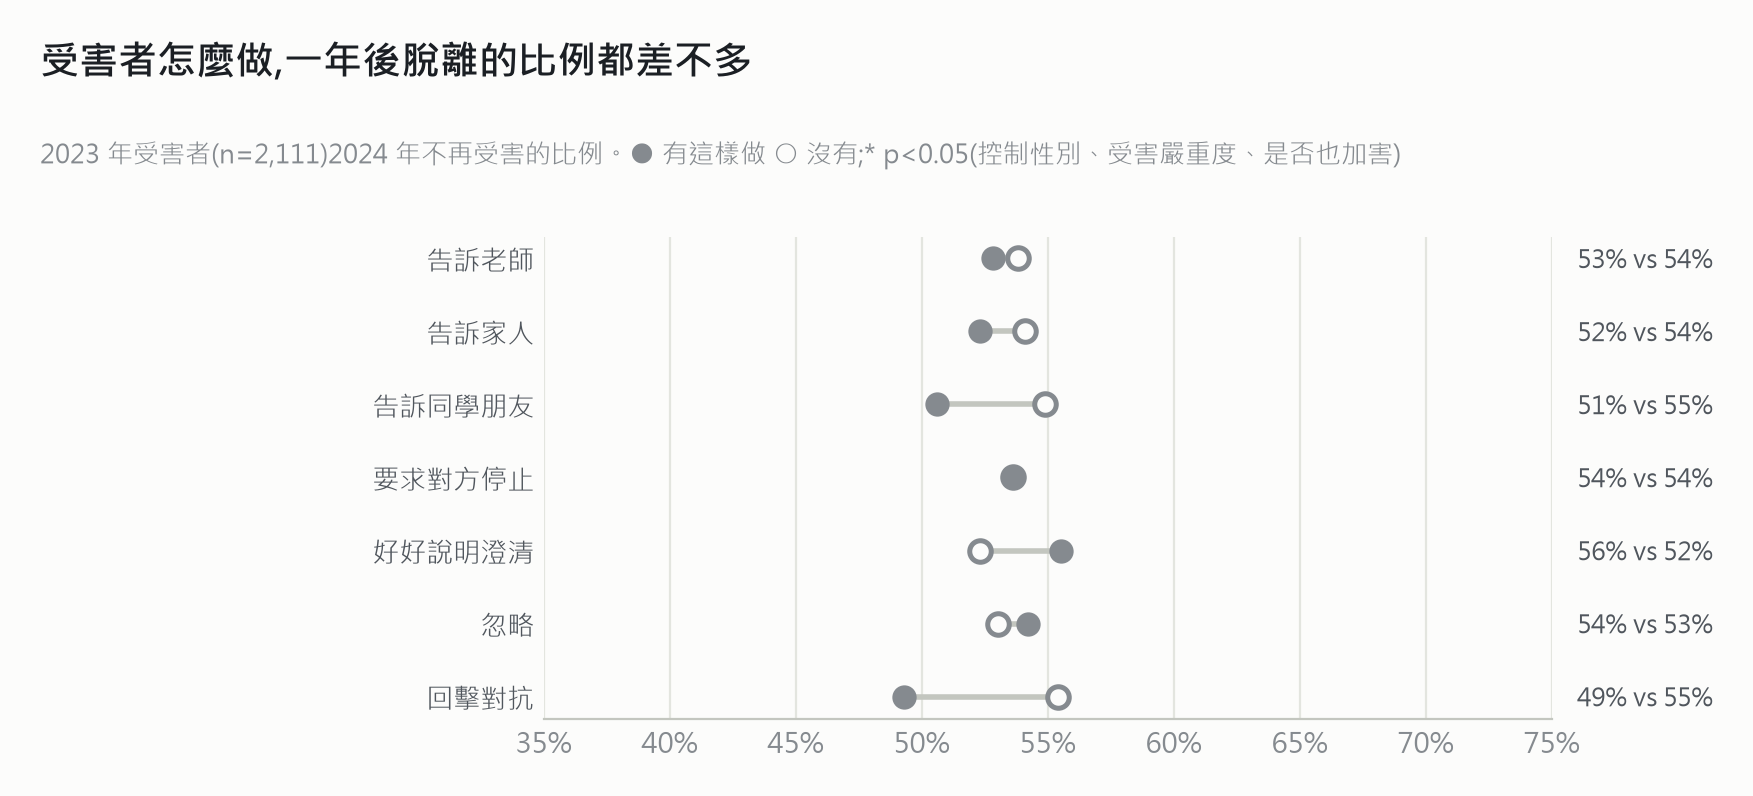

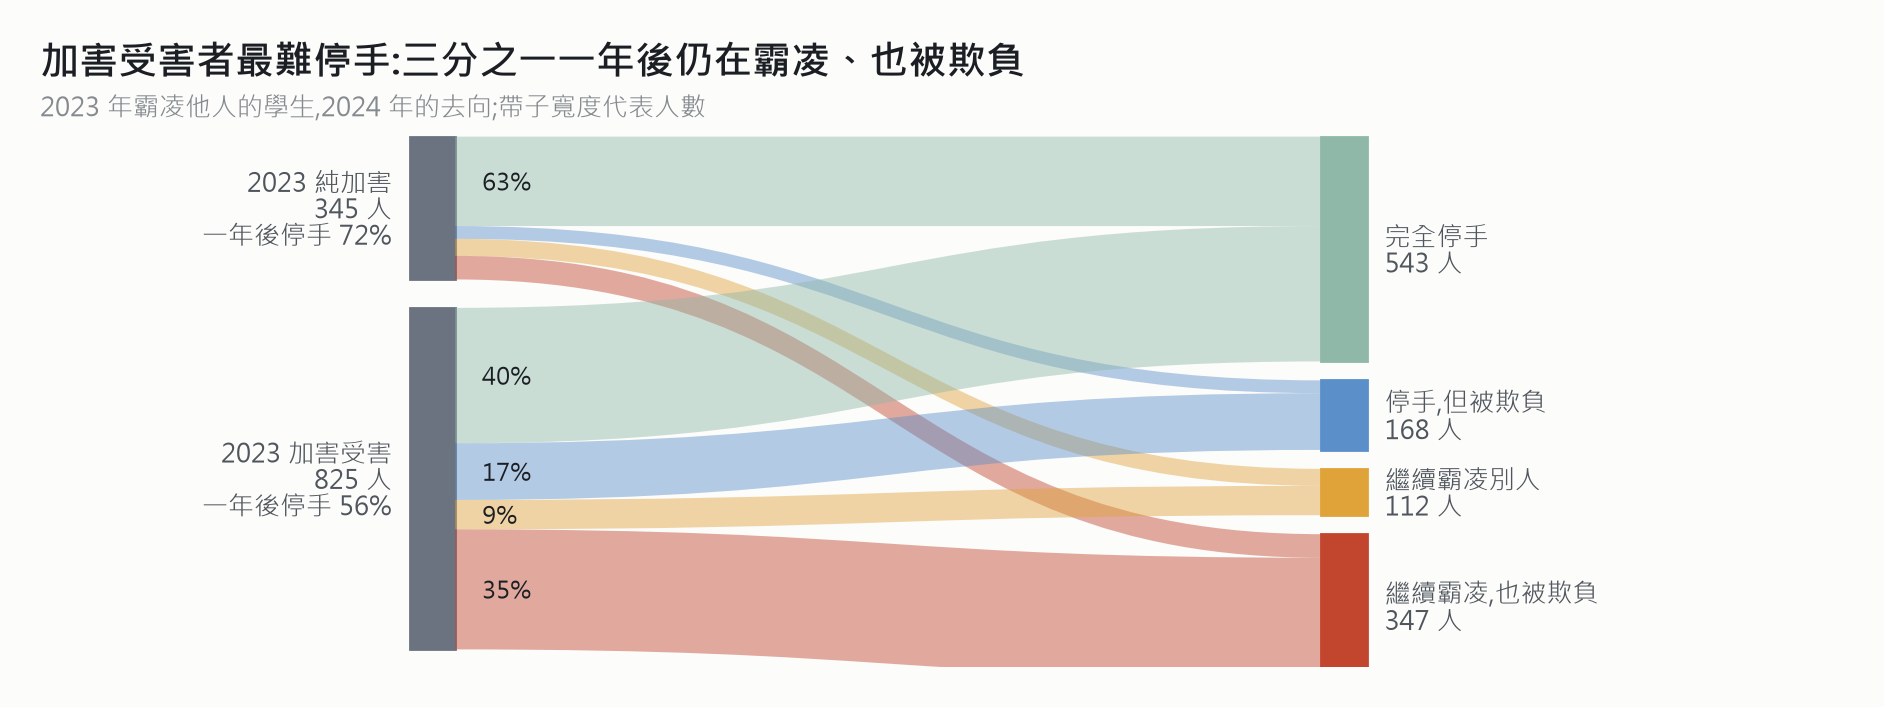

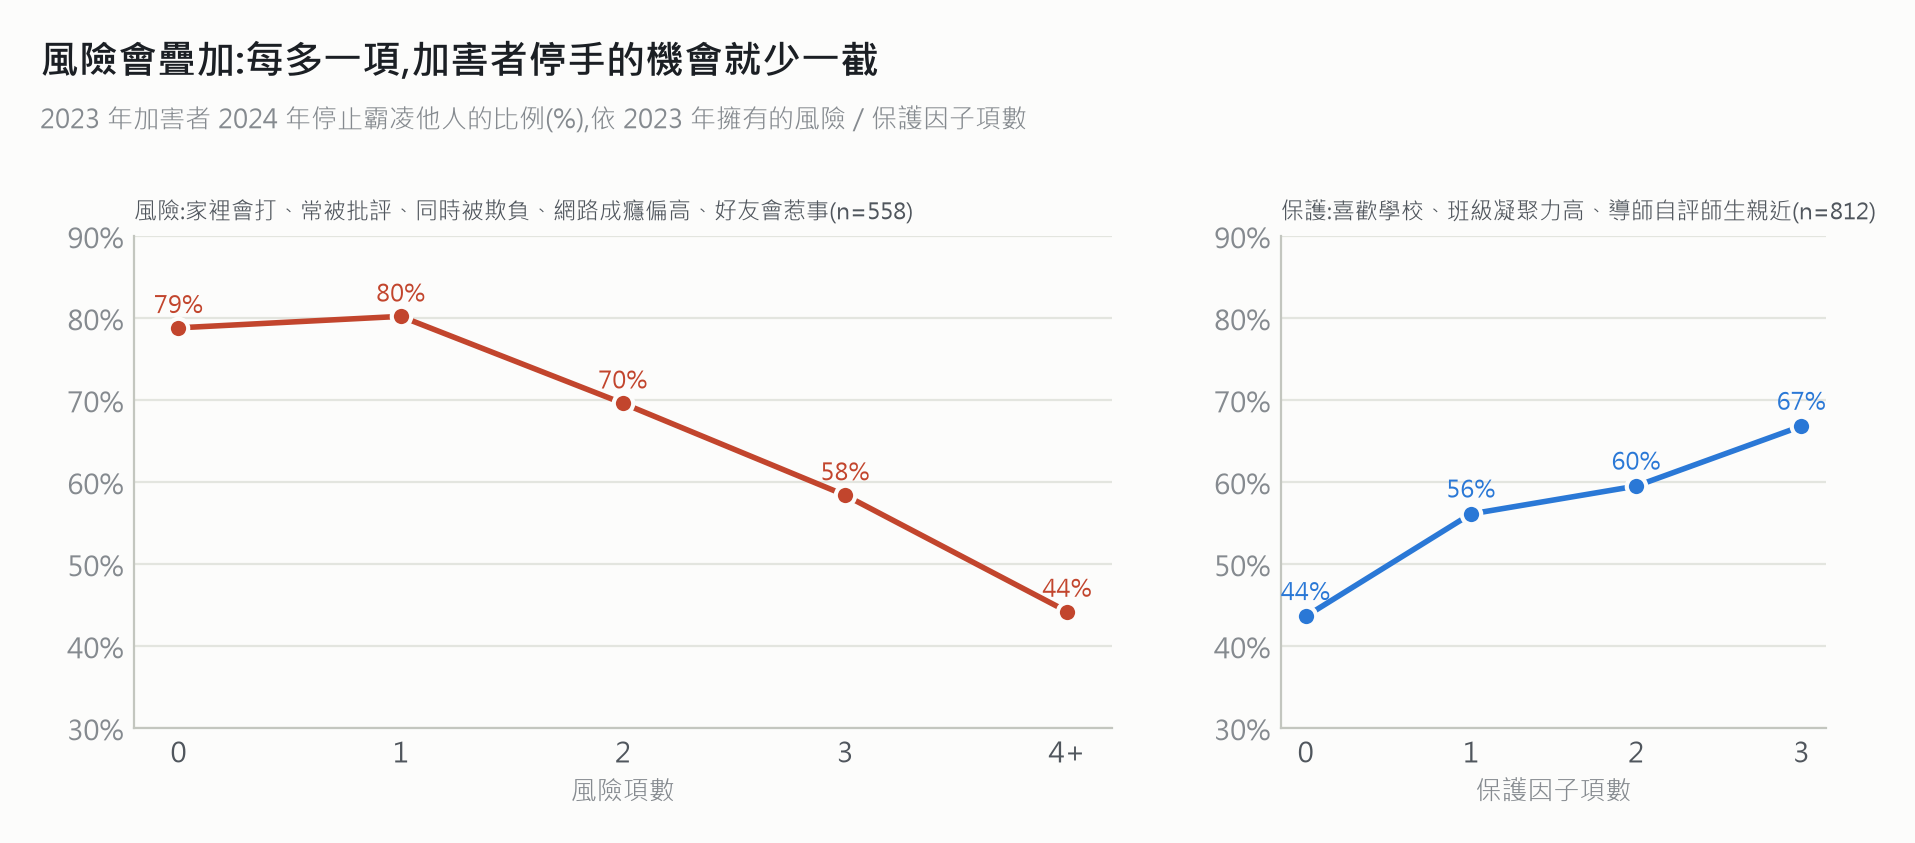

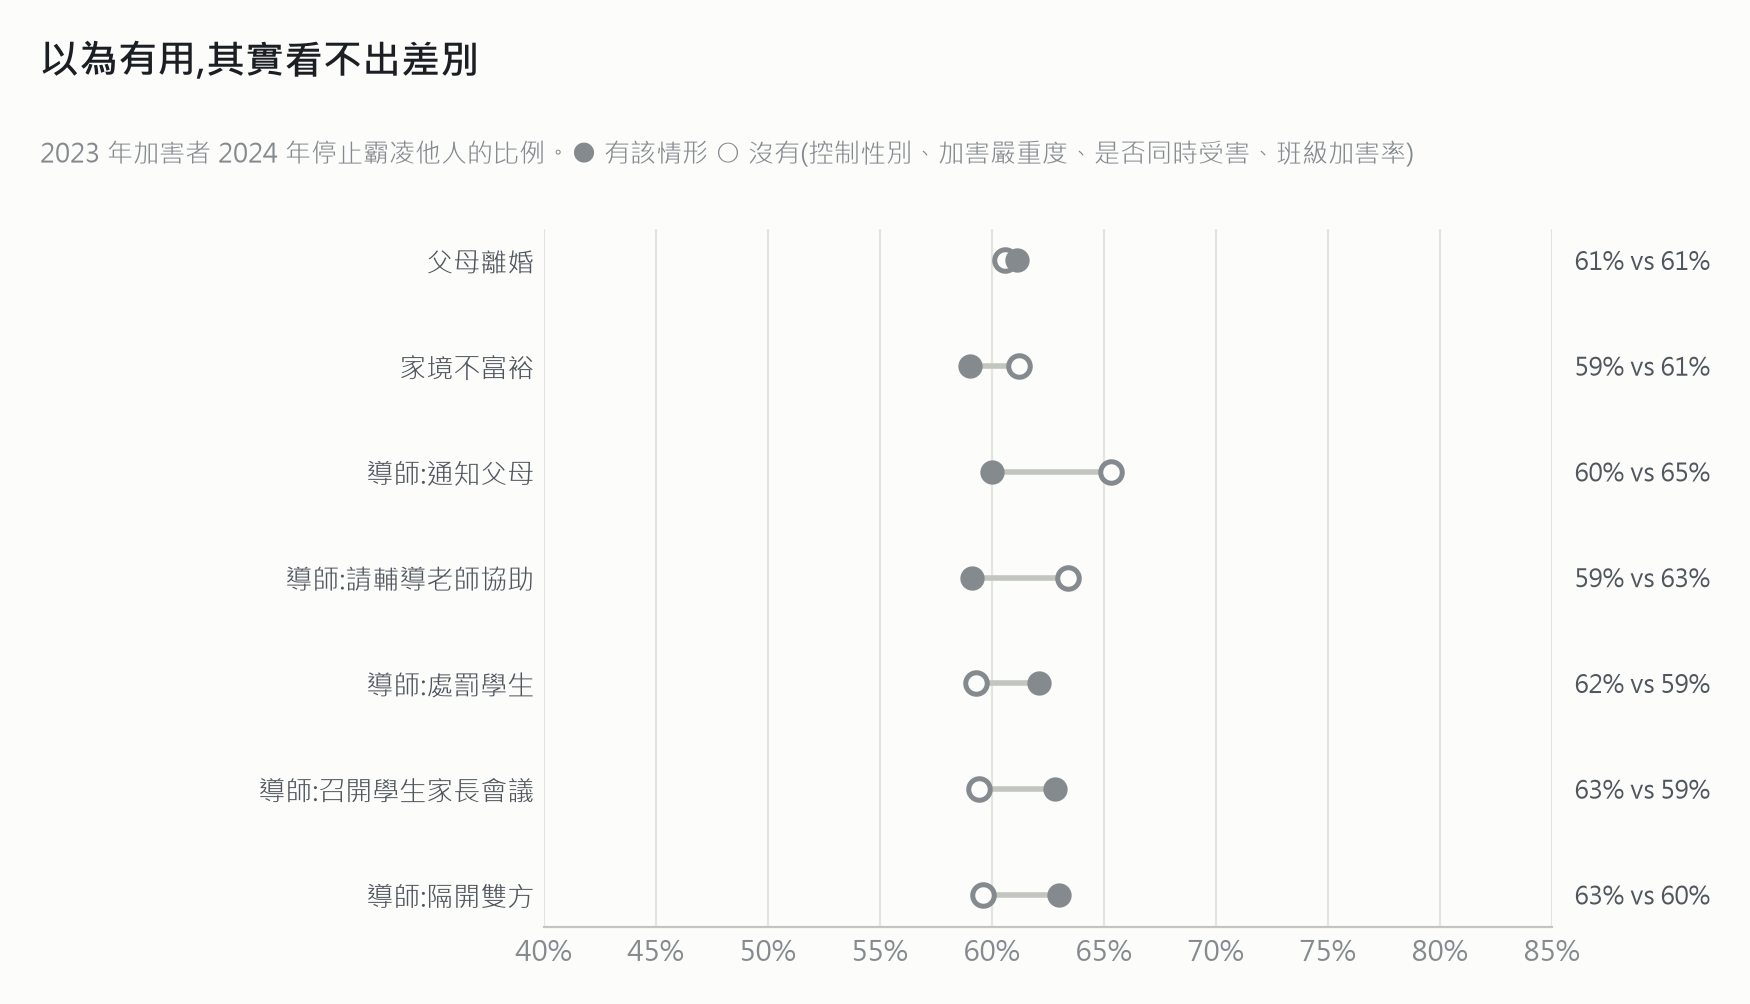

In [14]:
if HAS_DATA:
    from IPython.display import Image
    from bully import figures as F
    for p in [F.fig1_victim(vc), F.fig2_flow(fl), F.fig3_cumulative(cu), F.fig4_nohelp(nd)]:
        display(Image(filename=str(p), width=720))